# 12 — Eigenfaces, Fisherfaces e LBPH

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 12/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 12/16

> **Execução:** células principais executadas localmente no JupyterLab em 14/11/2026, conforme confirmação do autor.


### Materiais complementares

- [Guia Técnico](./reference_materials/12_eigenfaces_fisherfaces_lbph.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_eigenfaces_fisherfaces_lbph.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Explicar reconhecimento facial clássico e demonstrar técnicas sobre dados não biométricos.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Eigenfaces aplica PCA a imagens vetorizadas para encontrar direções de variância; Fisherfaces combina redução e discriminação supervisionada; LBPH resume padrões locais de textura em histogramas. Essas técnicas dependem de alinhamento, resolução e condições de captura. O laboratório utiliza dígitos como analogia matemática para não distribuir fotografias biométricas históricas.

### Conceito matemático

$$Z=(X-\mu)W_{PCA}$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
D=load_digits();a,b,ya,yb=train_test_split(D.data,D.target,stratify=D.target,random_state=4,test_size=.25)
pca=PCA(n_components=20,random_state=4).fit(a)
lda=LinearDiscriminantAnalysis().fit(pca.transform(a),ya)
print('PCA+LDA sobre dígitos (analogia):',round(accuracy_score(yb,lda.predict(pca.transform(b))),3),'variância PCA:',round(pca.explained_variance_ratio_.sum(),3))

PCA+LDA sobre dígitos (analogia): 0.949 variância PCA: 0.894


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

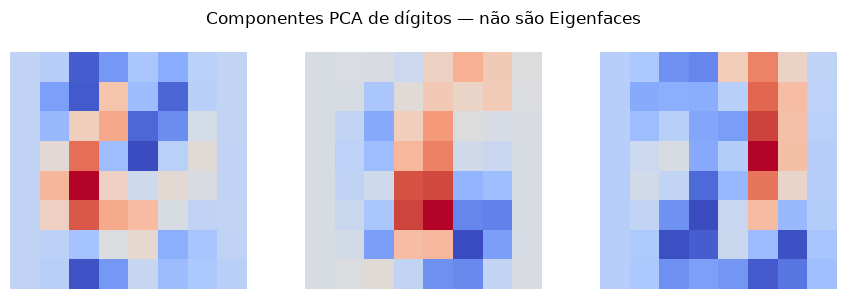

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(9,3))
for a,img in zip(ax,pca.components_[:3]):a.imshow(img.reshape(8,8),cmap='coolwarm');a.axis('off')
plt.suptitle('Componentes PCA de dígitos — não são Eigenfaces');plt.tight_layout();plt.show()

## Interpretação técnica

O experimento é analogia de PCA+LDA, não implementação de identificação biométrica. LBPH será discutido conceitualmente; requer cv2.face do OpenCV contrib para o módulo histórico.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Qual principal diferença entre PCA e LDA?

**Resolução comentada:** PCA maximiza variância sem rótulos; LDA procura direções discriminativas entre classes.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Não tratar componentes PCA de dígitos como eigenfaces reais, nem fornecer dataset facial sem licença.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Explicar reconhecimento facial clássico e demonstrar técnicas sobre dados não biométricos.
- **Mecanismo:** Eigenfaces aplica PCA a imagens vetorizadas para encontrar direções de variância; Fisherfaces combina redução e discriminação supervisionada; LBPH resume padrões locais de textura em histogramas.
- **Equação:** $Z=(X-\mu)W_{PCA}$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** divisão por identidade. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **divisão por identidade** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **divisão por identidade** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
